# linear regression
Let's predict a continuous value using a simple relationship: y = 3x + 2

Here true weight is 3 and true bias is 2 now we will generate some data and see whether pytorch can learn these values or not.

X shape:  torch.Size([100, 1])
y shape:  torch.Size([100, 1])


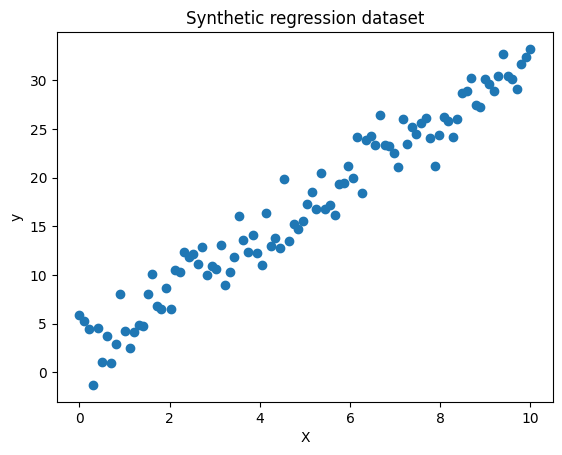

In [13]:
# step 1: Generate the data
import torch
import matplotlib.pyplot as plt

torch.manual_seed(42)

# Input Values
# linspace genrerates 100 evenly space values and reshape converts them into a column tensor shape of (100, 1)
X = torch.linspace(0, 10, 100).reshape(-1, 1)

# torch.randn_like(X) * 2 adds random noise so the points don't fall perfectly on a line.
y = 3 * X + 2 + torch.randn_like(X) * 2

print("X shape: ", X.shape)
print("y shape: ", y.shape)

plt.scatter(X.numpy(), y.numpy())
plt.xlabel("X")
plt.ylabel("y")
plt.title("Synthetic regression dataset")
plt.show()

In [14]:
# 2. Splitting them into training, validation and test set
from torch.utils.data import TensorDataset, random_split, DataLoader
dataset = TensorDataset(X, y)

train_size = 70
val_size = 15
test_size = 15

train_dataset, val_dataset, test_dataset = random_split(
    dataset,
    [train_size, val_size, test_size],
    generator=torch.Generator().manual_seed(42)
)

print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Test samples:", len(test_dataset))

Training samples: 70
Validation samples: 15
Test samples: 15


random_split() creates three subsets. Each sample retains its corresponding input and target.

Now create DataLoaders:

In [15]:
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False
)


We shuffle the training data to randomize the order in which samples are presented. For validation and testing, shuffling isn't necessary.

In [16]:
# Step:3 Training our first linear regression model and validate it
import torch.nn as nn

# 1. Create the model
model = nn.Linear(1, 1) # (1,1) no. of in and out features
# at start pytorch assign w and b auto
print(model.weight)
print(model.bias)

# 2. Define the loss function
criterian = nn.MSELoss()

# 3. Defining an optimizer
optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

# 4. Train the model
epochs = 200

for epoch in range(epochs):
  # Training
  model.train()
  train_loss_sum = 0.0
  train_count = 0

  for X_batch, y_batch in train_loader:
    predictions = model(X_batch)
    loss = criterian(predictions, y_batch)

    # it will zero all the previous gradients then backprop then update params
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    batch_size = X_batch.size(0)
    train_loss_sum += loss.item() * batch_size
    train_count += batch_size

  train_loss = train_loss_sum / train_count

  # Validation
  model.eval()
  val_loss_sum = 0.0
  val_count = 0

  with torch.no_grad():
    for X_batch, y_batch in val_loader:
        predictions = model(X_batch)
        loss = criterian(predictions, y_batch)

        batch_size = X_batch.size(0)
        val_loss_sum += loss.item() * batch_size
        val_count += batch_size

  val_loss = val_loss_sum / val_count

  if epoch % 10 == 0:
     print(
          f"Epoch {epoch:3d} | "
          f"Train loss: {train_loss:.4f} | "
          f"Validation loss: {val_loss:.4f}"
        )

print("Learned weight:", model.weight.item())
print("Learned bias:", model.bias.item())

Parameter containing:
tensor([[0.1564]], requires_grad=True)
Parameter containing:
tensor([-0.8799], requires_grad=True)
Epoch   0 | Train loss: 95.8128 | Validation loss: 2.9502
Epoch  10 | Train loss: 5.4396 | Validation loss: 2.2276
Epoch  20 | Train loss: 5.6011 | Validation loss: 1.9599
Epoch  30 | Train loss: 4.9226 | Validation loss: 1.9676
Epoch  40 | Train loss: 4.7361 | Validation loss: 1.5656
Epoch  50 | Train loss: 4.8658 | Validation loss: 2.0162
Epoch  60 | Train loss: 4.6182 | Validation loss: 1.4783
Epoch  70 | Train loss: 4.4853 | Validation loss: 2.2156
Epoch  80 | Train loss: 4.9427 | Validation loss: 1.3332
Epoch  90 | Train loss: 4.5350 | Validation loss: 1.4759
Epoch 100 | Train loss: 4.4670 | Validation loss: 1.2962
Epoch 110 | Train loss: 4.7957 | Validation loss: 1.4853
Epoch 120 | Train loss: 4.5332 | Validation loss: 1.4260
Epoch 130 | Train loss: 4.5595 | Validation loss: 1.3433
Epoch 140 | Train loss: 4.4947 | Validation loss: 1.9275
Epoch 150 | Train loss:

### 🔍 Code Explanation of Step 3: Training & Validation Loop

Let's break down exactly what happens in each part of the PyTorch loop during the training and validation phase:

#### 1. Training Mode (`model.train()`)
* **What it does:** This switches the model into "training" state.
* **Why it matters:** Some neural network layers (like Dropout or Batch Normalization) behave differently during training vs. testing. Calling `.train()` ensures these layers work correctly while learning.

#### 2. Gradient Resetting (`optimizer.zero_grad()`)
* **What it does:** It clears (zeroes out) the old slopes (gradients) calculated in the previous step.
* **Why it matters:** By default, PyTorch *accumulates* (adds up) gradients every time we call `.backward()`. If we forget to clear them, the new gradients will be added to the old ones, pointing the optimizer in the wrong direction.

#### 3. Backpropagation (`loss.backward()`)
* **What it does:** It computes the gradient (the direction and steepness of the error hill) of the loss function with respect to all learnable parameters (the Weight and Bias).

#### 4. Parameter Update (`optimizer.step()`)
* **What it does:** It takes a tiny step down the error hill by updating the parameters based on the calculated gradients and the learning rate ($lr=0.01$).

#### 5. Evaluation Mode (`model.eval()` & `torch.no_grad()`)
* **`model.eval()`**: Switches off training-only behaviors, putting the model in a pure "inference" state.
* **`with torch.no_grad()`**: Tells PyTorch **not** to calculate gradients while running this block of code. Since we are just testing the model and not training it here, disabling gradients saves a lot of memory and makes the computation run much faster.

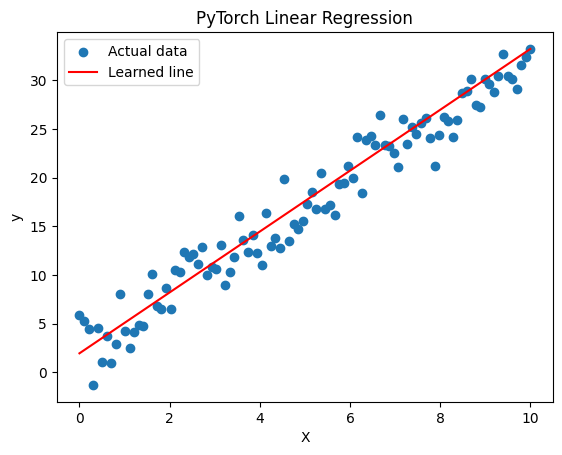

In [17]:
# Step 4: Visualizing our learned line
with torch.no_grad():
  predictions = model(X)

plt.scatter(X.numpy(), y.numpy(), label="Actual data")
plt.plot(X.numpy(), predictions.numpy(), color="red", label="Learned line")

plt.xlabel("X")
plt.ylabel("y")
plt.title("PyTorch Linear Regression")
plt.legend()
plt.show()

## Step 4: Testing our Model on Unseen Data

Now that we have trained our model and adjusted its weights using the training and validation sets, we must see how well it performs on completely new data that it has never seen before: the **test set**.

Evaluating our model on the test set gives us an unbiased estimate of its performance in the real world.

In [18]:
model.eval()
test_loss_sum = 0.0
test_count = 0

with torch.no_grad():
    for X_batch, y_batch in test_loader:
        predictions = model(X_batch)
        loss = criterian(predictions, y_batch)

        batch_size = X_batch.size(0)
        test_loss_sum += loss.item() * batch_size
        test_count += batch_size

test_loss = test_loss_sum / test_count
print(f"Final Test Loss (MSE): {test_loss:.4f}")

Final Test Loss (MSE): 4.1635


## Step 5: Enhanced Visualizations
Let's plot our actual training, validation, and test data points alongside the model's learned regression line to see how well it fits across all splits.

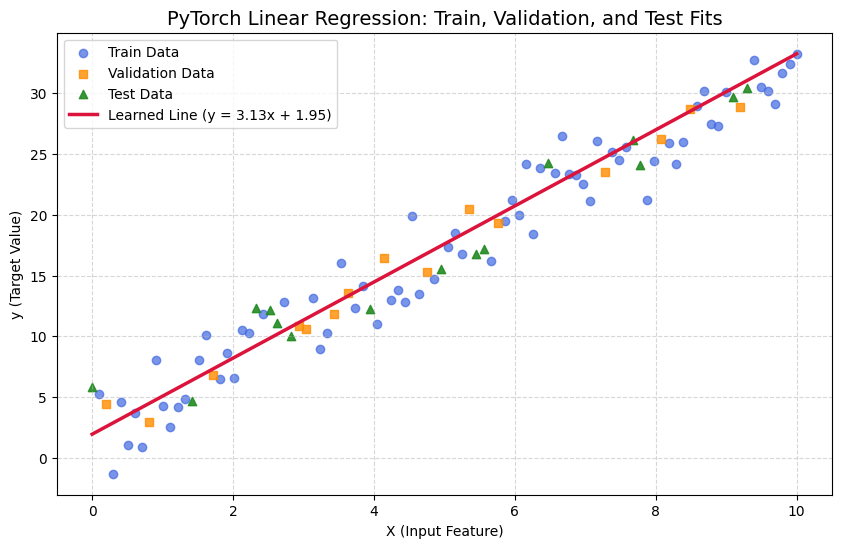

In [19]:
import numpy as np

# Extract data from datasets for plotting
X_train, y_train = zip(*[train_dataset[i] for i in range(len(train_dataset))])
X_val, y_val = zip(*[val_dataset[i] for i in range(len(val_dataset))])
X_test, y_test = zip(*[test_dataset[i] for i in range(len(test_dataset))])

X_train, y_train = torch.stack(X_train).numpy(), torch.stack(y_train).numpy()
X_val, y_val = torch.stack(X_val).numpy(), torch.stack(y_val).numpy()
X_test, y_test = torch.stack(X_test).numpy(), torch.stack(y_test).numpy()

# Generate model predictions for the entire range of X
with torch.no_grad():
    X_range = torch.linspace(0, 10, 100).reshape(-1, 1)
    y_pred = model(X_range).numpy()

plt.figure(figsize=(10, 6))
plt.scatter(X_train, y_train, color='royalblue', alpha=0.7, label='Train Data')
plt.scatter(X_val, y_val, color='darkorange', alpha=0.8, marker='s', label='Validation Data')
plt.scatter(X_test, y_test, color='forestgreen', alpha=0.9, marker='^', label='Test Data')
plt.plot(X_range.numpy(), y_pred, color='crimson', linewidth=2.5, label='Learned Line (y = {:.2f}x + {:.2f})'.format(model.weight.item(), model.bias.item()))

plt.xlabel('X (Input Feature)')
plt.ylabel('y (Target Value)')
plt.title('PyTorch Linear Regression: Train, Validation, and Test Fits', fontsize=14)
plt.legend(loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

## 🧸 Understanding Model Building (For Kids & Beginners!)

Let's break down what we just did using a simple analogy!

### 1. The Goal: Guessing the Rule
Imagine your friend has a secret rule for turning one number into another. For example, if you give them $2$, they output $8$. If you give them $4$, they output $14$.
Our goal is to build an artificial brain (the **Model**) that can guess this secret rule by looking at examples.

### 2. Step 1: The Model (Our Smart Guess-Machine)
In PyTorch, `nn.Linear(1, 1)` is our machine. It starts with a simple formula:
$$\text{Output} = (X \times \text{Weight}) + \text{Bias}$$
At the very beginning, the machine doesn't know anything, so it randomly guesses values for **Weight** and **Bias** (e.g., Weight = 0.28, Bias = -0.21).

### 3. Step 2: The Loss Function (The Scorekeeper)
How does our machine know if its guess was good or bad? We use a **Loss Function** (like `nn.MSELoss`).
Think of the loss function as a strict teacher who measures the distance between the machine's guess and the correct answer. The further away the guess is, the higher the **Loss score** (error). We want this score to be as close to zero as possible!

### 4. Step 3: The Optimizer (The Adjuster)
The **Optimizer** (like `SGD` - Stochastic Gradient Descent) is the mechanic. Every time the machine makes a mistake, the optimizer gently nudges the **Weight** and **Bias** in the right direction to make the error smaller next time. This nudging process is called **Backpropagation**.

### 5. Step 4: Training & Validation (Practice and Quizzes)
* **Training Set:** The practice worksheet. The machine looks at these examples repeatedly to learn and adjust its formula.
* **Validation Set:** A pop-quiz given during study sessions. It helps us check if the machine is actually understanding the patterns or just memorizing the practice answers.
* **Epochs:** Each epoch is one complete round of studying the whole worksheet.

### 6. Step 5: Testing (The Final Exam)
Once the machine is done studying, we give it the **Test Set** (the final exam). Because the machine has never seen these exact questions before, a high score here proves it has successfully learned the true secret rule!